# Sentence roles in medical abstracts: a PyTorch network from scratch, and the feature that matters most

**Module 04.1 · my implementation**, Seid Adem

> **The task in plain language.** Abstracts of clinical-trial papers follow a fixed structure: **background,
> objective, methods, results, conclusions**. Given one sentence, predict which part it belongs to. Tools that do this
> help researchers skim thousands of papers and help literature-mining systems find, for example, only the
> *results* sentences. The dataset is **PubMed 20k RCT**: about 20,000 randomised-controlled-trial abstracts with
> every sentence labelled. ([Background in Lesson 1–6](../LESSONS.md))

The course solved it twice: **1A**, TF-IDF → SVD → a scikit-learn MLP (test accuracy 0.635), and **1B**, fine-tuning
**PubMedBERT**, a 110-million-parameter biomedical transformer (0.853). This notebook:

1. **Builds the neural network myself in PyTorch:** a `Dataset`/`DataLoader`, an `nn.Module`, and a training loop with
   early stopping. The reusable code is in [`src/dsls/textclf.py`](../../../src/dsls/textclf.py) and is unit-tested.
2. **Checks the evaluation set-up** before trusting any number.
3. **Adds one piece of domain knowledge** (where the sentence sits in the abstract) and measures what it's worth.
4. **Compares everything on the same 29,578-sentence test set**, including the course's fine-tuned PubMedBERT.

In [1]:
import inspect
import time
import warnings
from pathlib import Path

import datasets
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import torch
from datasets import load_dataset
from sklearn.dummy import DummyClassifier
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, f1_score

from dsls.textclf import (
    MLPClassifier,
    make_loader,
    pick_device,
    position_features,
    predict_proba,
    train_with_early_stopping,
)

warnings.filterwarnings("ignore", category=FutureWarning)
datasets.utils.logging.set_verbosity_error()  # hide "repo card metadata" notices
FIGURES = Path("figures")
FIGURES.mkdir(exist_ok=True)
sns.set_theme(style="whitegrid", context="notebook")
SEED = 0
LABELS = [
    "background",
    "objective",
    "methods",
    "results",
    "conclusions",
]  # the order they appear in an abstract
DEVICE = pick_device()
print("device:", DEVICE, "| torch", torch.__version__)

device: mps | torch 2.15.0


## 1 · The data and its official splits

> **In plain language.** The dataset's authors split it **by abstract**: no abstract has sentences in more than one
> of train, validation and test. The course instead took the first 8,000 *sentences* of the training split and
> shuffled them into its own train/validation/test, so sentences from the same abstract land on both sides. In the
> crystallography module ([03.2](../../../03_foundations_of_machine_learning/02_hyperparameters_and_performance/implementation/))
> exactly this kind of sharing inflated a score from 0.74 to 0.93. Is it a problem here?

In [2]:
ds = load_dataset("armanc/pubmed-rct20k")
train, val, test = (ds[s].to_pandas() for s in ("train", "validation", "test"))
for df in (train, val, test):  # every sentence's abstract length, for position features later
    df["n_sentences"] = df.groupby("abstract_id")["sentence_id"].transform("max") + 1
    df["y"] = df["label"].map(LABELS.index)

summary = pd.DataFrame(
    {
        name: {"sentences": len(df), "abstracts": df["abstract_id"].nunique()}
        for name, df in [("train", train), ("validation", val), ("test", test)]
    }
).T
print(summary.to_string())
print(
    "abstracts shared between official train and test:", len(set(train.abstract_id) & set(test.abstract_id))
)
print("label shares (train):", train["label"].value_counts(normalize=True).round(3).to_dict())

            sentences  abstracts
train          176642      15000
validation      29672       2500
test            29578       2500
abstracts shared between official train and test: 0
label shares (train): {'methods': 0.336, 'results': 0.328, 'conclusions': 0.154, 'background': 0.104, 'objective': 0.078}


The classes are imbalanced: *methods* and *results* make up two-thirds of sentences, *objective* under 8 %. So
**macro-F1** (every class counts equally; see [04.2 lessons](../../02_evaluation_and_visualisation/LESSONS.md)) is
reported next to accuracy.

**Testing the course's split.** Same 8,000 sentences, same model (TF-IDF + logistic regression, explained in
section 2), split two ways:

In [3]:
def tfidf_logreg(train_df, test_df):
    vec = TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True)
    model = LogisticRegression(max_iter=3000, C=5).fit(vec.fit_transform(train_df["text"]), train_df["y"])
    pred = model.predict(vec.transform(test_df["text"]))
    return accuracy_score(test_df["y"], pred), f1_score(test_df["y"], pred, average="macro")


first8k = train.iloc[:8000].sample(frac=1, random_state=SEED)  # the course's working subset
by_sentence = (first8k.iloc[:4800], first8k.iloc[6400:])  # course-style 60/20/20 by sentence
abstracts = first8k["abstract_id"].unique()
rng = np.random.default_rng(SEED)
rng.shuffle(abstracts)
cut60, cut80 = int(0.6 * len(abstracts)), int(0.8 * len(abstracts))
by_abstract = (
    first8k[first8k.abstract_id.isin(abstracts[:cut60])],
    first8k[first8k.abstract_id.isin(abstracts[cut80:])],
)

for name, (tr, te) in [("split by sentence (course)", by_sentence), ("split by abstract", by_abstract)]:
    acc, f1 = tfidf_logreg(tr, te)
    shared = te["abstract_id"].isin(tr["abstract_id"]).mean()
    print(
        f"{name:28s} test sentences whose abstract is in training: {shared:4.0%}  accuracy {acc:.3f}  macro-F1 {f1:.3f}"
    )

split by sentence (course)   test sentences whose abstract is in training: 100%  accuracy 0.731  macro-F1 0.640


split by abstract            test sentences whose abstract is in training:   0%  accuracy 0.758  macro-F1 0.672


**No inflation here.** Every test sentence of the course split shares its abstract with training sentences, yet the
score isn't higher than with a split by abstract (it's slightly lower, within noise). A sentence's *role* (is it a
method? a result?) isn't something you can look up from its abstract's topic, unlike a crystal's outcome.

> **In plain language.** The same check gave opposite answers in two modules: a big inflation for crystals and none
> here. **Don't assume leakage, and don't assume its absence: measure it.** From here on I use the official splits
> anyway: they're the standard, and results are comparable with published work.

## 2 · Baselines first

> **In plain language.** Before any neural network, measure two reference points:
> * a **no-skill baseline** that always predicts the most common class;
> * **TF-IDF + logistic regression**, the classic strong text baseline. **TF-IDF** turns each sentence into word
>   weights (a word scores high if frequent in this sentence but rare overall). Using single words *and* word pairs
>   ("bigrams", like *"were randomized"*) captures some phrasing. Logistic regression then learns one weight per word
>   and class.

To match the course's scale, the first experiments use **400 training abstracts (4,732 sentences)**, about the
course's 4,800. Everything is evaluated on the full official test set (29,578 sentences from 2,500 unseen abstracts).

In [4]:
small = train[train["abstract_id"].isin(train["abstract_id"].unique()[:400])]
results = []


def record(name, data, y_pred, seconds):
    results.append(
        {
            "model": name,
            "training sentences": data,
            "accuracy": accuracy_score(test["y"], y_pred),
            "macro-F1": f1_score(test["y"], y_pred, average="macro"),
            "training seconds": seconds,
        }
    )


majority = DummyClassifier(strategy="most_frequent").fit(small[["y"]], small["y"])
record("majority class", len(small), majority.predict(test[["y"]]), 0)

start = time.perf_counter()
vec_small = TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True, max_features=50_000)
X_small = vec_small.fit_transform(small["text"])
logreg = LogisticRegression(max_iter=3000, C=5).fit(X_small, small["y"])
record(
    "TF-IDF + logistic regression",
    len(small),
    logreg.predict(vec_small.transform(test["text"])),
    time.perf_counter() - start,
)
pd.DataFrame(results).round(3)

,model,training sentences,accuracy,macro-F1,training seconds
0,majority class,4732,0.334,0.100,0.000
1,TF-IDF + logistic regression,4732,0.758,0.676,1.102


**Plain logistic regression already scores far above the course's 1A network** (0.635 accuracy, 0.535 macro-F1 on a
course test split of similar difficulty). The 1A pipeline made two feature choices that are common in text tutorials:

* **removing English stop words** (`stop_words="english"`), i.e. dropping very common words such as *we, was, were,
  to, this, not*;
* **compressing** the 20,000 TF-IDF columns to 256 with **SVD** (a PCA-like method for text).

Which one costs accuracy? Same logistic regression, same 20,000-feature vocabulary, the four combinations:

In [5]:
from sklearn.decomposition import TruncatedSVD

rows = []
for stop_words in (None, "english"):
    for n_svd in (None, 256):
        vec = TfidfVectorizer(ngram_range=(1, 2), max_features=20_000, stop_words=stop_words)
        X_tr, X_te = vec.fit_transform(small["text"]), vec.transform(test["text"])
        if n_svd:
            svd = TruncatedSVD(n_components=n_svd, random_state=SEED)
            X_tr, X_te = svd.fit_transform(X_tr), svd.transform(X_te)
        pred = LogisticRegression(max_iter=3000, C=5).fit(X_tr, small["y"]).predict(X_te)
        rows.append(
            {
                "stop words": "removed" if stop_words else "kept",
                "SVD": f"{n_svd} dims" if n_svd else "none",
                "accuracy": accuracy_score(test["y"], pred),
                "macro-F1": f1_score(test["y"], pred, average="macro"),
            }
        )
pd.DataFrame(rows).round(3)

,stop words,SVD,accuracy,macro-F1
0,kept,none,0.756,0.673
1,kept,256 dims,0.727,0.641
2,removed,none,0.690,0.585
3,removed,256 dims,0.655,0.538


**Removing stop words is the main cost (−0.09 macro-F1); SVD adds a smaller one (−0.03).** With both, logistic
regression lands at 0.538, the same as the course's network (0.535). So the 1A network wasn't held back by being a
network; it was held back by its features.

> **In plain language.** "Remove stop words" is standard advice for *topic* tasks (what is this document about?).
> This task is about *role*, and role is carried precisely by the small words: "**We** aimed **to** …" (objective),
> "Patients **were** randomized …" (methods), "… **was** significantly lower …" (results). **Preprocessing must
> fit the question.** A step that helps one task can quietly ruin another.

## 3 · The neural network, built in PyTorch

> **In plain language.** PyTorch asks you to write three things yourself, and each maps onto an idea from the
> [lessons](../LESSONS.md#lesson-3--how-a-network-learns-the-training-loop):
>
> | Piece | Job | Here |
> |-------|-----|------|
> | **Data loader** | serves the data in small **batches** | TF-IDF rows are stored sparsely (mostly zeros) and turned into dense numbers one batch at a time, so even 176,000 sentences × 50,000 word features fit in memory |
> | **Model (`nn.Module`)** | turns inputs into one score per class | input → dropout → 256 hidden neurons (ReLU) → dropout → 5 outputs |
> | **Training loop** | forward pass → loss → backpropagation → weight update, repeated | AdamW optimiser, cross-entropy loss; after every epoch score the validation set; **stop when it stops improving** and keep the best weights |
>
> **Dropout** randomly switches off a fraction of inputs and neurons during training, so the network can't rely on
> any single word. It's a standard defence against overfitting.

The training loop, as written in `dsls.textclf`:

In [6]:
print(inspect.getsource(train_with_early_stopping))

def train_with_early_stopping(
    model: nn.Module,
    train_loader: DataLoader,
    val_loader: DataLoader,
    score_fn: Callable[[np.ndarray, np.ndarray], float],
    max_epochs: int = 30,
    patience: int = 3,
    lr: float = 1e-3,
    weight_decay: float = 1e-4,
    device=None,
    seed: int = 0,
) -> list[dict]:
    """Train with AdamW and cross-entropy; after each epoch score the validation set with ``score_fn(y, pred)``.

    Stops after ``patience`` epochs without improvement and **restores the best weights**. Returns one dict per
    epoch (training loss, validation loss, validation score, seconds), handy for learning curves.
    """
    torch.manual_seed(seed)
    device = device or pick_device()
    model.to(device)
    optimiser = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=weight_decay)
    loss_fn = nn.CrossEntropyLoss()
    y_val = torch.cat([y for _, y in val_loader]).numpy()

    history, best_score, best_state, waited = [], -np.inf, None, 0
    for 

In [7]:
def train_mlp(train_df, vectorizer, use_position, label, max_epochs=30, patience=3):
    # Fit the network on train_df (TF-IDF features, optionally + position) and evaluate on the test set.
    def features(df):
        extra = position_features(df["sentence_id"], df["n_sentences"]) if use_position else None
        return vectorizer.transform(df["text"]), extra

    X_tr, e_tr = features(train_df)
    X_va, e_va = features(val)
    X_te, e_te = features(test)
    n_inputs = X_tr.shape[1] + (e_tr.shape[1] if use_position else 0)
    model = MLPClassifier(n_inputs, len(LABELS), seed=SEED)
    start = time.perf_counter()
    history = train_with_early_stopping(
        model,
        make_loader(X_tr, train_df["y"], e_tr, batch_size=256, shuffle=True, seed=SEED),
        make_loader(X_va, val["y"], e_va, batch_size=1024),
        score_fn=lambda y, p: f1_score(y, p, average="macro"),
        max_epochs=max_epochs,
        patience=patience,
        device=DEVICE,
        seed=SEED,
    )
    seconds = time.perf_counter() - start
    proba = predict_proba(model, make_loader(X_te, None, e_te, batch_size=1024), DEVICE)
    record(label, len(train_df), proba.argmax(1), seconds)
    return pd.DataFrame(history), proba


hist_mlp, _ = train_mlp(small, vec_small, use_position=False, label="PyTorch MLP (TF-IDF)")
pd.DataFrame(results).round(3)

,model,training sentences,accuracy,macro-F1,training seconds
0,majority class,4732,0.334,0.100,0.000
1,TF-IDF + logistic regression,4732,0.758,0.676,1.102
2,PyTorch MLP (TF-IDF),4732,0.756,0.671,20.209


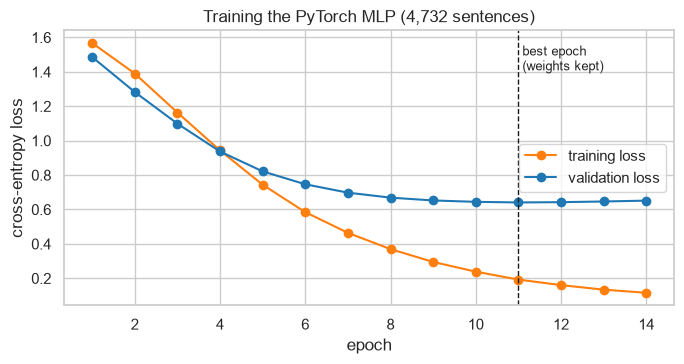

In [8]:
fig, ax1 = plt.subplots(figsize=(7, 3.8))
ax1.plot(hist_mlp["epoch"], hist_mlp["train_loss"], marker="o", label="training loss", color="tab:orange")
ax1.plot(hist_mlp["epoch"], hist_mlp["val_loss"], marker="o", label="validation loss", color="tab:blue")
best = hist_mlp.loc[hist_mlp["val_score"].idxmax(), "epoch"]
ax1.axvline(best, color="k", ls="--", lw=1)
ax1.text(best, ax1.get_ylim()[1] * 0.95, " best epoch\n (weights kept)", va="top", fontsize=9)
ax1.set(xlabel="epoch", ylabel="cross-entropy loss", title="Training the PyTorch MLP (4,732 sentences)")
ax1.legend(loc="center right")
fig.tight_layout()
fig.savefig(FIGURES / "01_mlp_training_curve.png", dpi=150)
plt.show()

**Reading the curve.** Training loss keeps falling while validation loss flattens from about epoch 8: the network
starts memorising its 4,732 sentences. Early stopping kept the weights from the best validation epoch (11).

**Result: the PyTorch MLP ties logistic regression** (macro-F1 0.671 vs 0.676). On word-count features, an extra
hidden layer has nothing to add: the signal is mostly "which words appear", and a linear model captures that. A
network only earns its complexity when it gets inputs or structure a linear model can't use.

## 4 · Domain knowledge: *where* the sentence is

> **In plain language.** A human skimming an abstract barely needs to read a sentence to guess its role: the first
> sentences set the scene, the middle describes methods, then results, and the last sentence concludes. A model that
> sees one sentence at a time has no idea where it was. But **at prediction time the position is always known** (you
> have the whole abstract), so it's a legitimate input, not leakage.

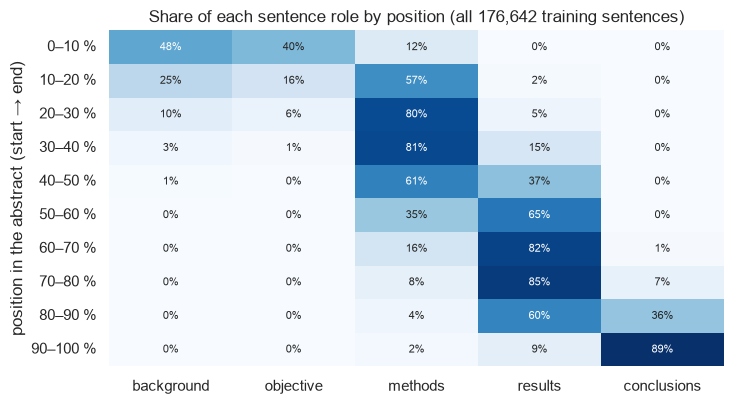

In [9]:
rel = train["sentence_id"] / (train["n_sentences"] - 1).clip(lower=1)
share = pd.crosstab(
    pd.cut(rel, np.linspace(0, 1, 11), include_lowest=True), train["label"], normalize="index"
)[LABELS]
share.index = [f"{int(i.left * 100)}–{int(i.right * 100)} %" for i in share.index]
fig, ax = plt.subplots(figsize=(7.5, 4.2))
sns.heatmap(share, annot=True, fmt=".0%", cmap="Blues", cbar=False, ax=ax, annot_kws={"fontsize": 8})
ax.set(
    xlabel="",
    ylabel="position in the abstract (start → end)",
    title="Share of each sentence role by position (all 176,642 training sentences)",
)
fig.tight_layout()
fig.savefig(FIGURES / "02_role_by_position.png", dpi=150)
plt.show()

The pattern is strong: the first tenth of an abstract is mostly background and objective, the middle is methods, and
the last tenth is mostly conclusions. I add **12 position numbers** to every sentence's word features: relative
position, abstract length, and a "which tenth" indicator (`position_features`, unit-tested).

In [10]:
hist_pos, _ = train_mlp(small, vec_small, use_position=True, label="PyTorch MLP (TF-IDF + position)")
pd.DataFrame(results).round(3)

,model,training sentences,accuracy,macro-F1,training seconds
0,majority class,4732,0.334,0.100,0.000
1,TF-IDF + logistic regression,4732,0.758,0.676,1.102
2,PyTorch MLP (TF-IDF),4732,0.756,0.671,20.209
3,PyTorch MLP (TF-IDF + position),4732,0.853,0.797,22.875


**+12 numbers, +0.13 macro-F1.** The same network on the same 4,732 sentences jumps from 0.671 to **0.797** macro-F1
(accuracy 0.756 → 0.853) once it knows where each sentence sits. That is the largest single improvement in this
notebook, bigger than any change of model.

## 5 · More data: all 176,642 training sentences

> **In plain language.** The course used 4,800 sentences, under 3 % of the available training data, to keep
> training fast. How much do the models gain from all of it? (The TF-IDF vocabulary is refitted on the full
> training set, still capped at the 50,000 most frequent words and word pairs.)

In [11]:
start = time.perf_counter()
vec_full = TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True, max_features=50_000)
X_full = vec_full.fit_transform(train["text"])
logreg_full = LogisticRegression(max_iter=3000, C=5).fit(X_full, train["y"])
record(
    "TF-IDF + logistic regression",
    len(train),
    logreg_full.predict(vec_full.transform(test["text"])),
    time.perf_counter() - start,
)
hist_full, _ = train_mlp(
    train, vec_full, use_position=False, label="PyTorch MLP (TF-IDF)", max_epochs=10, patience=2
)
hist_full_pos, proba_best = train_mlp(
    train, vec_full, use_position=True, label="PyTorch MLP (TF-IDF + position)", max_epochs=10, patience=2
)
pd.DataFrame(results).round(3)

,model,training sentences,accuracy,macro-F1,training seconds
0,majority class,4732,0.334,0.100,0.000
1,TF-IDF + logistic regression,4732,0.758,0.676,1.102
2,PyTorch MLP (TF-IDF),4732,0.756,0.671,20.209
3,PyTorch MLP (TF-IDF + position),4732,0.853,0.797,22.875
4,TF-IDF + logistic regression,176642,0.817,0.747,22.436
5,PyTorch MLP (TF-IDF),176642,0.823,0.755,154.306
6,PyTorch MLP (TF-IDF + position),176642,0.885,0.833,178.518


## 6 · The same test set for the course's PubMedBERT

The course's notebook 1B saved its fine-tuned PubMedBERT locally (`make runnable` → run 1B). Its training
sentences come from the first 8,000 sentences of the official *training* split, so the official test set is unseen
by it too. Scoring it here makes the comparison fair. If the checkpoint isn't on this machine, the cell says so and
the reference row is skipped.

In [12]:
COURSE_MODEL = Path("../course_materials/local/runnable/artifacts/session1B_transformer/best_model")
if COURSE_MODEL.exists():
    from transformers import AutoModelForSequenceClassification, AutoTokenizer

    tokenizer = AutoTokenizer.from_pretrained(COURSE_MODEL)
    bert = AutoModelForSequenceClassification.from_pretrained(COURSE_MODEL).to(DEVICE).eval()
    course_labels = [bert.config.id2label[i] for i in range(bert.config.num_labels)]
    texts = test["text"].tolist()
    order = np.argsort([len(t) for t in texts])  # batch similar lengths together: less padding, faster
    preds = np.empty(len(texts), dtype=int)
    start = time.perf_counter()
    with torch.no_grad():
        for i in range(0, len(texts), 128):
            idx = order[i : i + 128]
            enc = tokenizer(
                [texts[j] for j in idx], truncation=True, max_length=128, padding=True, return_tensors="pt"
            ).to(DEVICE)
            preds[idx] = bert(**enc).logits.argmax(-1).cpu().numpy()
    preds = np.array([LABELS.index(course_labels[p]) for p in preds])
    record(
        "PubMedBERT fine-tuned (course 1B)", 4800, preds, np.nan
    )  # trained elsewhere; see notebook 02 for timing
    print(f"scored {len(texts):,} sentences in {time.perf_counter() - start:.0f} s (inference only)")
else:
    print("course checkpoint not found; run `make runnable` and the 1B notebook to include it")

scored 29,578 sentences in 128 s (inference only)


In [13]:
table = pd.DataFrame(results)
table["training seconds"] = table["training seconds"].round(0)
table = table.round(3).sort_values(["training sentences", "macro-F1"])
table

,model,training sentences,accuracy,macro-F1,training seconds
0,majority class,4732,0.334,0.100,0.0
2,PyTorch MLP (TF-IDF),4732,0.756,0.671,20.0
1,TF-IDF + logistic regression,4732,0.758,0.676,1.0
3,PyTorch MLP (TF-IDF + position),4732,0.853,0.797,23.0
7,PubMedBERT fine-tuned (course 1B),4800,0.850,0.782,NaN
4,TF-IDF + logistic regression,176642,0.817,0.747,22.0
5,PyTorch MLP (TF-IDF),176642,0.823,0.755,154.0
6,PyTorch MLP (TF-IDF + position),176642,0.885,0.833,179.0


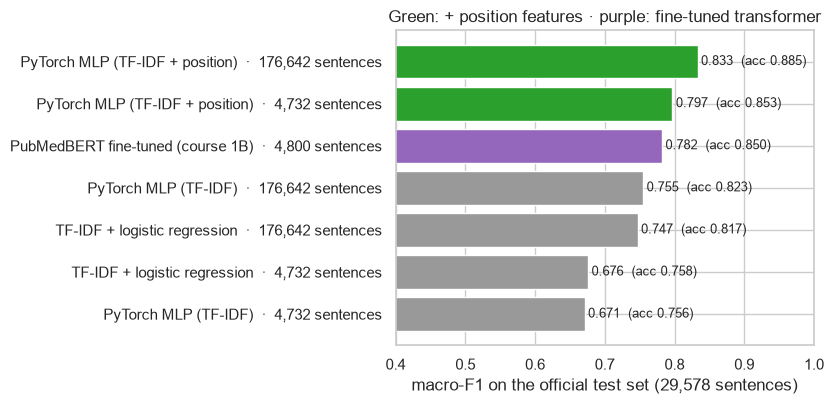

In [14]:
plot = table[table["model"] != "majority class"].copy()
plot["setting"] = plot["model"] + "  ·  " + plot["training sentences"].map(lambda n: f"{n:,} sentences")
plot = plot.sort_values("macro-F1")
fig, ax = plt.subplots(figsize=(8.5, 4.2))
colors = ["tab:green" if "position" in m else ("tab:purple" if "BERT" in m else "0.6") for m in plot["model"]]
ax.barh(plot["setting"], plot["macro-F1"], color=colors)
for y, (f1, acc) in enumerate(zip(plot["macro-F1"], plot["accuracy"], strict=True)):
    ax.text(f1 + 0.005, y, f"{f1:.3f}  (acc {acc:.3f})", va="center", fontsize=9)
ax.set(
    xlim=(0.4, 1.0),
    xlabel="macro-F1 on the official test set (29,578 sentences)",
    title="Green: + position features · purple: fine-tuned transformer",
)
fig.tight_layout()
fig.savefig(FIGURES / "03_model_comparison.png", dpi=150)
plt.show()

Per-class view of the best model, to see which roles remain hard:

In [15]:
print(classification_report(test["y"], proba_best.argmax(1), target_names=LABELS, digits=3))

              precision    recall  f1-score   support

  background      0.719     0.790     0.753      3077
   objective      0.723     0.575     0.641      2333
     methods      0.919     0.941     0.930      9884
     results      0.916     0.920     0.918      9713
 conclusions      0.937     0.914     0.925      4571

    accuracy                          0.885     29578
   macro avg      0.843     0.828     0.833     29578
weighted avg      0.884     0.885     0.884     29578



**Reading the comparison** (all rows: the same 29,578 test sentences from 2,500 unseen abstracts)

* **The small MLP with position features matches the course's fine-tuned PubMedBERT:** macro-F1 0.797 vs 0.782,
  accuracy 0.853 vs 0.850, with about the same amount of training data. It trained in **25 seconds**, has no
  pre-training at all, and is 25× smaller (4.4 M vs 110 M parameters). PubMedBERT reads each sentence far better
  than word counts do, but it was never told *where* the sentence was. (The course's run took 3 h 15 min, but
  [notebook 02](02_small_biomedical_transformers.ipynb) shows that was mostly a 35-minute stall and other pauses: the
  same fine-tuning takes about 5 minutes on this laptop.)
* **More data helps every model** (+0.07–0.08 macro-F1 from 4.7k to 177k sentences), and the best model overall is
  the MLP with position on the full data: **macro-F1 0.833, accuracy 0.885**, trained in about 3 minutes.
* **With position known, the hardest distinction is *objective* vs *background*** (F1 0.64 and 0.75). Both sit at the
  start of the abstract, so position can't separate them, and their wording overlaps ("To assess …" vs "… remains
  unclear").

*Fairness notes:* the PubMedBERT checkpoint is the course's own run (3 epochs, default settings), not a tuned one,
and it trained on 4,800 sentences sampled from the first 8,000 training rows vs my 4,732 from 400 abstracts.
[Notebook 02](02_small_biomedical_transformers.ipynb) fine-tunes transformers under identical conditions, including
ones that are also given the position: PubMedBERT then reaches 0.847.

## Conclusions

1. **Built in PyTorch from first principles:** a sparse-to-dense data loader, an `nn.Module` MLP with dropout, and a
   training loop with early stopping that restores the best weights. All reusable and unit-tested in `dsls.textclf`.
2. **Check the evaluation set-up, and accept a null result:** sharing abstracts between train and test did *not*
   inflate scores here (unlike the crystals in 03.2). The official abstract-level splits are used anyway.
3. **Strong simple baselines first, and preprocessing must fit the question:** TF-IDF + logistic regression
   (macro-F1 0.676) beats the course's 1A network (0.535). The direct comparison shows why: removing stop words cost
   0.09 and SVD compression 0.03. Together they reproduce the course's score with a linear model.
4. **Domain knowledge can be worth more than model size.** Adding the sentence's position (12 numbers) raised
   macro-F1 by 0.13 and let a 25-second, 4.4-million-parameter MLP match the course's 110-million-parameter
   transformer. Given the same information, the transformer goes further (0.847, notebook 02).
5. **More data still helps:** the full training set lifts the best model to macro-F1 0.833 / accuracy 0.885.

---
*Data: PubMed 20k RCT (Dernoncourt & Lee, 2017) via the Hugging Face dataset `armanc/pubmed-rct20k`, downloaded to
the local Hugging Face cache, not redistributed here. Runtime about 10 minutes on an Apple-silicon laptop (GPU via
MPS), most of it the full-data runs and PubMedBERT inference.*